Shortest Path:
A -> B -> E -> G
Total Cost: 8


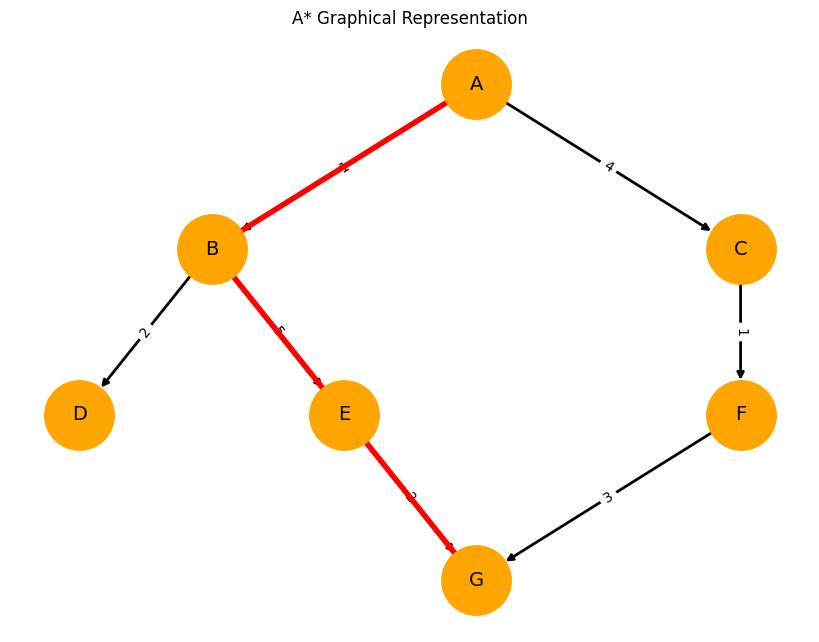

In [15]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt

#Define the graph with edge costs
graph = {
    'A': [('B',1),('C',4)],
    'B': [('D',2),('E',5)],
    'C': [('F',1)],
    'D': [],
    'E': [('G',2)],
    'F': [('G',3)],
    'G': []
}

#Heuristic values
heuristic = {
    'A':7,
    'B':6,
    'C':2,
    'D':5,
    'E':2,
    'F':1,
    'G':8
}

#A* Algorithm
def astar(graph, heuristic, start, goal):
    pq = [(heuristic[start],0,start,[start])]
    visited = set()
    while pq:
        f,g,node,path=heapq.heappop(pq)

        if node == goal:
            return path,g

        if node in visited:
            continue

        visited.add(node)

        for neighbor,cost in graph[node]:
            new_g = g + cost
            new_f = new_g + heuristic[neighbor]
            heapq.heappush(pq, (new_f,new_g,neighbor,path +[neighbor]))

    return None,float('inf')

# Run A*
path, cost = astar(graph,heuristic ,'A','G')
print("Shortest Path:")
print(" -> ".join(path))
print("Total Cost:",cost)
G = nx.DiGraph()

#add edges with weights

for node in graph :
    for neighbor , weight in graph[node]:
        G.add_edge(node,neighbor , weight = weight)
pos={'A':(0,3),'B':(-1,2),'C':(1,2),'C':(1,2),'D':(-1.5,1),'E':(-0.5,1),'F':(1,1),'G':(0,0)}
plt.figure(figsize=(8,6))

#draw nodes and edges

nx.draw(G,pos,with_labels=True,node_color='orange',node_size=2500,font_size=14,edge_color='black',arrows=True,width=2)

#draw edge lables(costs)
edge_lables=nx.get_edge_attributes(G,'weight')
nx.draw_networkx_edge_labels(G,pos,edge_labels=edge_labels)
path_edges=list(zip(path[:-1],path[1:]))
nx.draw_networkx_edges(G,pos,
                       edgelist=path_edges,
                       edge_color='red',
                       width=4,
                       arrows=True
                      )
plt.title("A* Graphical Representation")
plt.axis('off')
plt.show()

Optimal Solution Path:
A->C->F
Total Cost: 6


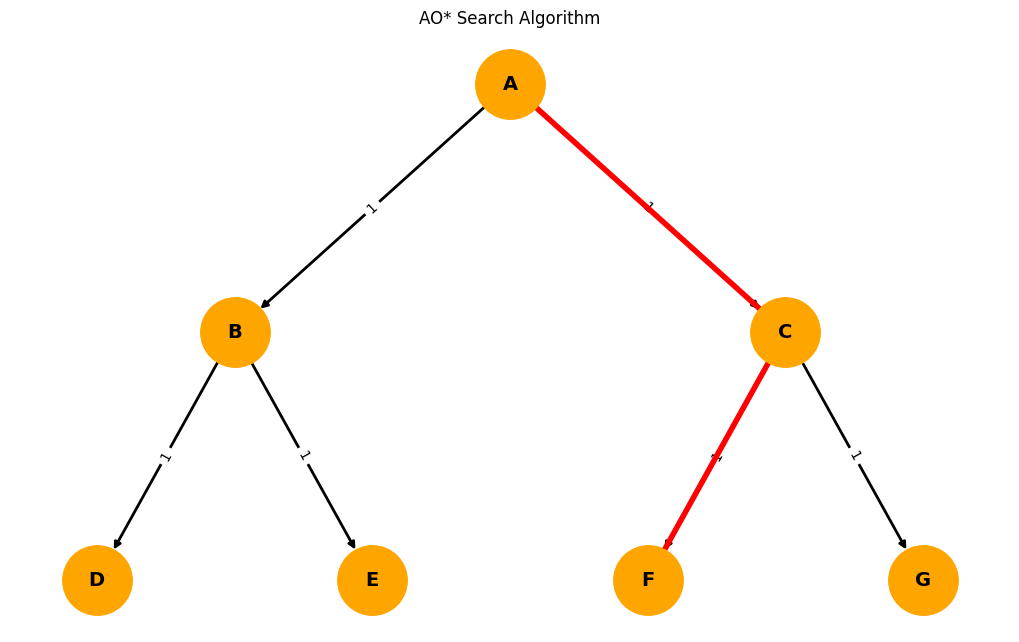

In [29]:
import networkx as nx
import matplotlib.pyplot as plt

graph = {
    'A':{'type':'OR', 'children': [('B',1),('C',1)]},
    'B':{'type':'AND', 'children':[('D',1),('E',1)]},
    'C':{'type':'OR', 'children': [('F',1),('G',1)]},
    'D':{'type':'LEAF','cost':2},
    'E':{'type':'LEAF','cost':3},
    'F':{'type':'LEAF','cost':4},
    'G':{'type':'LEAF','cost':6}
}
def ao_star(node):
    info = graph[node]

    if info['type'] == 'LEAF':
        return info['cost'],[node]

    if info['type'] == 'OR':
        best_cost = float('inf')
        best_path = []

        for child, edge_cost in info['children']:
            child_cost, child_path = ao_star(child)
            total = edge_cost + child_cost

            if total < best_cost:
                best_cost = total
                best_path = [node] + child_path
        return best_cost, best_path

    if info['type'] == 'AND':
        total_cost = 0
        full_path = [node]

        for child, edge_cost in info['children']:
            child_cost, child_path = ao_star(child)
            total_cost += edge_cost + child_cost
            full_path += child_path

        return total_cost, full_path

cost, path = ao_star('A')

print("Optimal Solution Path:")
print("->".join(path))
print("Total Cost:",cost)


G= nx.DiGraph()
for node,info in graph.items():
    if 'children' in info:
        for child, weight in info['children']:
            G.add_edge(node, child, weight=weight)
pos= {
    'A': (0,3),
    'B': (-1,2),
    'C': (1,2),
    'D': (-1.5, 1),
    'E': (-0.5, 1),
    'F': (0.5, 1),
    'G': (1.5, 1)
}
plt.figure(figsize=(10,6))
colors= []
for n in G.nodes():
    t= graph[n]['type']
    if t== 'OR':
        colors.append('skyblue')
    elif t== 'AND':
        colors.append('lightgreen')
    else:
        colors.append('orange')
nx.draw(G, pos, with_labels=True, node_size=2500, node_color='orange', font_size=14, font_weight='bold', arrows=True, width=2)
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

# Highlight the shortest path
path_edges = list(zip(path[:-1], path[1:]))
nx.draw_networkx_edges(G, pos, edgelist=path_edges, width=4, edge_color='red', arrows= True)   

plt.title("AO* Search Algorithm")
plt.axis('off')
plt.show()



